# Optimal transport: feasibility before cost

Finite balanced transport with cost C_ij=(x_i-y_j)^2. Compare direct Sinkhorn, log-domain Sinkhorn and unregularized HiGHS LP. An independent 1D weighted monotone coupling verifies LP costs. Rounding repairs feasibility, not entropy bias or optimality. Numerical primal-dual bounds are checked with float64 tolerances; they are not interval-arithmetic certificates.

In [1]:
import json
from pathlib import Path
r=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:',r['success'])
print('Checks:',r['checks'])
print('Summary:',r['summary'])

Predeclared gate: True
Checks: {'log_all_finite': True, 'max_rounded_residual': 4.527628272299467e-16, 'max_reference_discrepancy': 5.551115123125783e-16, 'max_scaled_bound_violation': 0.0, 'max_separated_relative_cost_error': 5.940299556073114e-06, 'naive_failed_all_selected': True, 'false_low_cost_detected': True}
Summary: [{'method': 'naive', 'total': 36, 'failed': 6, 'nonconverged': 0, 'max_raw_residual': 9.960410968234967e-10, 'max_rounded_residual': 4.501607420159814e-16}, {'method': 'log', 'total': 36, 'failed': 0, 'nonconverged': 1, 'max_raw_residual': 0.00024523353173425133, 'max_rounded_residual': 4.527628272299467e-16}]


In [2]:
print('Two-atom adversarial experiment:')
for name,value in r['adversarial'].items():
    print(name,value)
assert r['adversarial']['raw_residual']>1
assert abs(r['adversarial']['rounded_cost']-.8)<1e-12

Two-atom adversarial experiment:
reference 0.8
raw_cost 3.0173949583280115e-43
rounded_cost 0.8000000000000002
raw_residual 1.6000000000000003
rounded_residual 2.220446049250313e-16
lower 0.014326966884775272
converged False
raw_plan [[0.10000000000000002, 3.0132615405768774e-43], [4.133417751134321e-46, 0.8999999999999999]]
rounded_plan [[0.1, 0.8000000000000002], [4.592686390149246e-47, 0.1]]


In [3]:
print('n=64, epsilon=.005:')
for row in r['selected']:
    print(row['scenario'],row['method'],'failure:',row['failed'],'LP:',row['reference'],'repaired cost:',row['upper'],'converged:',row['converged'])

n=64, epsilon=.005:
overlap naive failure: False LP: 0.0867507413565811 repaired cost: 0.08886677751259546 converged: True
overlap log failure: False LP: 0.0867507413565811 repaired cost: 0.08886677751259546 converged: True
separated naive failure: True LP: 400.0 repaired cost: None converged: False
separated log failure: False LP: 400.0 repaired cost: 400.00237611982243 converged: True
mass_mismatch naive failure: False LP: 0.8650877635004611 repaired cost: 0.8650883560992482 converged: True
mass_mismatch log failure: False LP: 0.8650877635004611 repaired cost: 0.8650883560992483 converged: True


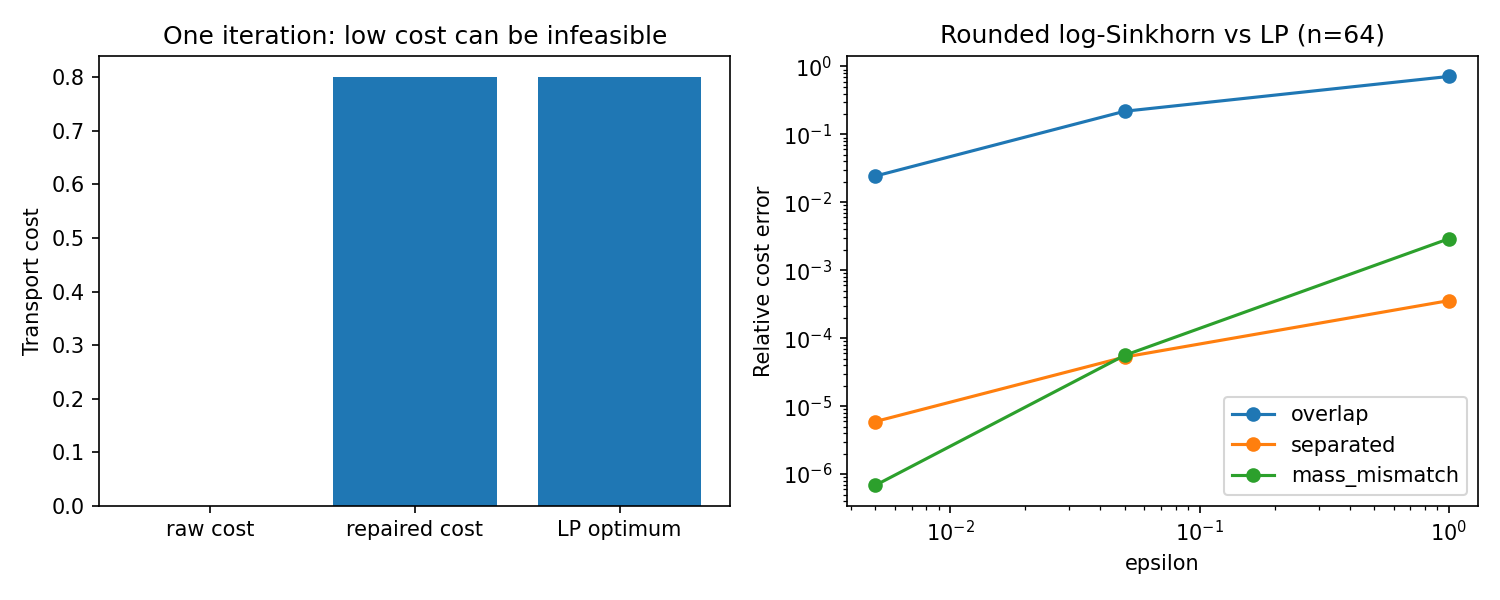

In [4]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

## Conclusions

A near-zero cost may be infeasible and is not evidence of an improved transport solver. Log-domain updates avoid the observed kernel underflow, but do not ensure fast convergence. Feasible rounding gives an upper bound, not the exact optimum; entropy and early-stopping errors remain. One-dimensional synthetic cases do not establish multivariate performance or causal distributional dynamics. See informe.md for assumptions, prior art, raw failures and limitations.